# <span style="color:red"> Lecture 20: JSON </span>

<font size = "4">

In this class we will:

- Learn what JSON is, and how it relates to Python dictionaries and lists
- Convert between JSON text and Python objects with the `json` library
- Navigate the nested structure of real data from the chess.com API
- Convert JSON data into a Pandas DataFrame

In [1]:
import json # Python's built-in module for working with JSON

import pandas as pd
import matplotlib.pyplot as plt

<font size = "4">

chess.com shares data about its players and games through an API (Application Programming Interface). Next class we will request data from it directly; today we work with files already downloaded from it, stored in the folder "chess_raw_data".

The data covers eight of the world's best online players:

| Username | Player |
| --- | --- |
| Hikaru | Hikaru Nakamura |
| GHANDEEVAM2003 | Arjun Erigaisi |
| Firouzja2003 | Alireza Firouzja |
| FabianoCaruana | Fabiano Caruana |
| GMWSO | Wesley So |
| DenLaz | Denis Lazavik |
| HansOnTwitch | Hans Niemann |
| LyonBeast | Maxime Vachier-Lagrave |

Each player carries a separate rating per "time control", i.e. how much time each player gets for the whole game:

- bullet: a minute or two
- blitz: a few minutes
- rapid: ten minutes or more
- daily: days per move

Ratings rise or fall after every game, and a higher rating means a stronger player.


# <span style="color:red"> I. What is JSON? </span>

<font size = "4">

- JSON stands for **JavaScript Object Notation**.
- It is a text format that programs use to exchange data.
- When you request data from a website's API, it almost always arrives as JSON.
- JSON looks almost identical to Python dictionaries and lists:

| JSON | Python |
| --- | --- |
| object `{ }` | dictionary |
| array `[ ]` | list |
| string `"..."` | string |
| number | integer or float |
| `true` / `false` | `True` / `False` |
| `null` | `None` |

<font size = "4">

Below is a small piece of JSON describing a made-up chess player. In Python it is just a string; triple quotes let the string span multiple lines.


In [2]:
player_text = """
{
    "username": "datasci185_student",
    "title": null,
    "followers": 12,
    "is_streamer": false,
    "ratings": {"bullet": 812, "blitz": 950},
    "favorite_openings": ["Italian Game", "London System"]
}
"""

print(type(player_text))
print(player_text)

<class 'str'>

{
    "username": "datasci185_student",
    "title": null,
    "followers": 12,
    "is_streamer": false,
    "ratings": {"bullet": 812, "blitz": 950},
    "favorite_openings": ["Italian Game", "London System"]
}



<font size = "4">

The `json` library turns JSON text into Python objects. The function for that is `json.loads`, short for "load string":


In [3]:
player = json.loads(player_text)

print(type(player))
print(player)

<class 'dict'>
{'username': 'datasci185_student', 'title': None, 'followers': 12, 'is_streamer': False, 'ratings': {'bullet': 812, 'blitz': 950}, 'favorite_openings': ['Italian Game', 'London System']}


<font size = "4">

- `null` became `None`, and `false` became `False`.
- The JSON object became a dictionary. Inside it, `"ratings"` is a dictionary and `"favorite_openings"` is a list.
- From here on, it's an ordinary Python dictionary:

In [4]:
print(player["username"])
print(player["title"])
print(player["ratings"]["blitz"])
print(player["favorite_openings"][0])

datasci185_student
None
950
Italian Game


<font size = "4">

`json.dumps` ("dump string") does the reverse, turning Python objects into JSON text. Passing `indent` indents the result so it is easier to read.


In [5]:
player_text_again = json.dumps(player, indent = 4)

print(type(player_text_again))
print(player_text_again)

<class 'str'>
{
    "username": "datasci185_student",
    "title": null,
    "followers": 12,
    "is_streamer": false,
    "ratings": {
        "bullet": 812,
        "blitz": 950
    },
    "favorite_openings": [
        "Italian Game",
        "London System"
    ]
}


<font size = "4">

JSON is stricter than Python:

- Strings must use **double** quotes
- `true`, `false`, and `null` are lowercase
- Keys must be strings

In [6]:
bad_text = "{'username': 'datasci185_student'}"

# "as error" stores the error message in a variable called error
try:
    json.loads(bad_text)
except json.JSONDecodeError as error:
    print("Not valid JSON:", error)

Not valid JSON: Expecting property name enclosed in double quotes: line 1 column 2 (char 1)


In [7]:
# Integer keys are allowed in Python dictionaries, but not in JSON
round_winners = {1: "Hikaru", 2: "Firouzja2003"}

print(json.dumps(round_winners))
print(json.loads(json.dumps(round_winners)))   # the keys came back as strings!

{"1": "Hikaru", "2": "Firouzja2003"}
{'1': 'Hikaru', '2': 'Firouzja2003'}


<font size = "4">

**Exercise:** Below is a simplified version of one real game.

- Convert `game_text` with `json.loads` and store the result in a variable called `game`.
- Print the username of the player with the black pieces.
- Print the rating of the player with the white pieces.

In [8]:
game_text = """
{
    "url": "https://www.chess.com/game/live/184724304638",
    "time_class": "blitz",
    "rated": true,
    "white": {"username": "Firouzja2003", "rating": 3294, "result": "win"},
    "black": {"username": "General_Consensus", "rating": 3156, "result": "timeout"},
    "accuracies": {"white": 89.35, "black": 89.39}
}
"""

# your code here

game = json.loads(game_text)
print(game["black"]["username"])

General_Consensus


# <span style="color:red"> II. Reading and Writing JSON Files </span>

<font size = "4">

JSON is usually stored in files ending in ".json". Before Python can use a file, it has to open it.

`open(file_name, mode, encoding = "utf-8")` returns a file object: a connection to the file on your computer.

- `file_name`: the location of the file, e.g. "chess_raw_data/profile_hikaru.json"
- `mode`: what we want to do with the file
    - `"r"`: read (the default)
    - `"w"`: write. This creates the file, or **erases** it if it already exists!
- `encoding = "utf-8"`: makes sure names with accents and other special characters are read correctly on both Mac and Windows

A file should be closed when we're done with it, so that everything we wrote is saved and other programs can use the file.

The `with` keyword handles closing for us:

- The file is open only inside the indented block below `with`.
- `as file` names the file object `file` inside the block.
- When the block ends, Python closes the file automatically, even if an error happens inside.


In [9]:
help("with")

The "with" statement
********************

The "with" statement is used to wrap the execution of a block with
methods defined by a context manager (see section With Statement
Context Managers). This allows common "try"…"except"…"finally" usage
patterns to be encapsulated for convenient reuse.

   with_stmt:          "with" ( "(" with_stmt_contents ","? ")" | with_stmt_contents ) ":" suite
   with_stmt_contents: with_item ("," with_item)*
   with_item:          expression ["as" target]

The execution of the "with" statement with one “item” proceeds as
follows:

1. The context expression (the expression given in the "with_item") is
   evaluated to obtain a context manager.

2. The context manager’s "__enter__()" is loaded for later use.

3. The context manager’s "__exit__()" is loaded for later use.

4. The context manager’s "__enter__()" method is invoked.

5. If a target was included in the "with" statement, the return value
   from "__enter__()" is assigned to it.

   Note:

     The 

In [10]:
with open("chess_raw_data/profile_hikaru.json", "r", encoding = "utf-8") as file:
    profile_text = file.read()    # .read() returns the whole file as one string

# The block has ended, so we can confirm the file is closed
print(file.closed)

print(type(profile_text))

profile = json.loads(profile_text)
print(type(profile))

True
<class 'str'>
<class 'dict'>


<font size = "4">

`json.load` (no "s") does both steps at once: it reads the file and converts the JSON.

| Function | Converts |
| --- | --- |
| `json.loads` | JSON **string** → Python |
| `json.dumps` | Python → JSON **string** |
| `json.load` | JSON **file** → Python |
| `json.dump` | Python → JSON **file** |

In [11]:
with open("chess_raw_data/profile_hikaru.json", "r", encoding = "utf-8") as file:
    profile = json.load(file)

print(type(profile))

<class 'dict'>


In [12]:
profile

{'avatar': 'https://images.chesscomfiles.com/uploads/v1/user/15448422.88c010c1.200x200o.3c5619f5441e.png',
 'player_id': 15448422,
 '@id': 'https://api.chess.com/pub/player/hikaru',
 'url': 'https://www.chess.com/member/Hikaru',
 'name': 'Hikaru Nakamura',
 'username': 'hikaru',
 'title': 'GM',
 'followers': 1427877,
 'country': 'https://api.chess.com/pub/country/US',
 'location': 'Florida',
 'last_online': 1794325077,
 'joined': 1389043258,
 'status': 'premium',
 'is_streamer': True,
 'twitch_url': 'https://twitch.tv/gmhikaru',
 'verified': False,
 'league': 'Legend',
 'streaming_platforms': [{'type': 'twitch',
   'channel_url': 'https://twitch.tv/gmhikaru'}]}

<font size = "4">

Browsing JSON files in VS Code

- Open "chess_raw_data/profile_hikaru.json" from the file explorer in VS Code.
- These files were saved with 4-space indentation, which makes the nested structure easy to see.
- Hover next to the line numbers: the small arrows collapse and expand each level.

You can try this on "chess_raw_data/stats_hikaru.json": open it in VS Code, collapse "chess_blitz", then expand it again.

<font size = "4">

Writing works the same way, with mode `"w"` and `json.dump`:

In [13]:
my_players = {"favorite": "Hikaru",
              "also_watching": ["Firouzja2003", "GMWSO"]}

with open("my_players.json", "w", encoding = "utf-8") as file:
    json.dump(my_players, file, indent = 4)

# read it back in
with open("my_players.json", "r", encoding = "utf-8") as file:
    print(json.load(file))

{'favorite': 'Hikaru', 'also_watching': ['Firouzja2003', 'GMWSO']}


# <span style="color:red"> III. Navigating the Nested Structure </span>

<font size = "4">

Browse keys in the "first level"

In [14]:
with open("chess_raw_data/stats_hikaru.json", "r", encoding = "utf-8") as file:
    stats = json.load(file)

print(type(stats))

# The "len" command counts the keys
print(len(stats))

# The "keys" method extracts the names of the "first-level" objects
print(stats.keys())

<class 'dict'>
8
dict_keys(['chess_daily', 'chess960_daily', 'chess_rapid', 'chess_bullet', 'chess_blitz', 'fide', 'tactics', 'puzzle_rush'])


<font size = "4">

- Most keys are time controls: "chess_bullet", "chess_blitz", ...
- A few are something else: "fide" (his rating in over-the-board tournaments), "tactics", "puzzle_rush".

Browse the subdictionary within a particular key

In [15]:
stats["chess_blitz"]

{'last': {'rating': 3464, 'date': 1794334422, 'rd': 30},
 'best': {'rating': 3503,
  'date': 1791303699,
  'game': 'https://www.chess.com/game/live/184580310677'},
 'record': {'win': 36193, 'loss': 5562, 'draw': 4391}}

<font size = "4">

Each time control has three parts:

- "last": the current rating, the date it last changed, and "rd" (rating deviation: how uncertain the rating is)
- "best": the highest rating ever, with the date and a link to the game
- "record": the number of wins, losses, and draws

In [16]:
print(stats["chess_blitz"]["last"])
print(stats["chess_blitz"]["last"]["rating"])
print(stats["chess_blitz"]["record"])

{'rating': 3464, 'date': 1794334422, 'rd': 30}
3464
{'win': 36193, 'loss': 5562, 'draw': 4391}


<font size = "4">

Gradually work through the nested structure! Check the type at every level:

In [17]:
print(type(stats))
print(type(stats["chess_blitz"]))
print(type(stats["chess_blitz"]["last"]))
print(type(stats["chess_blitz"]["last"]["rating"]))

# Not every key holds a dictionary!
print(type(stats["fide"]))

<class 'dict'>
<class 'dict'>
<class 'dict'>
<class 'int'>
<class 'int'>


<font size = "4">

Dates come in as Unix timestamps, i.e. the number of seconds since January 1, 1970. `pd.to_datetime` with `unit = "s"` converts them to dates.


In [18]:
last_date = stats["chess_blitz"]["last"]["date"]

print(last_date)
print(pd.to_datetime(last_date, unit = "s"))

1794334422
2026-11-10 18:13:42


<font size = "4">

Every time control has the same structure, so we can loop over them:

In [19]:
time_controls = ["chess_bullet", "chess_blitz", "chess_rapid", "chess_daily"] 
time_controls2 = ["chess_bullet", "chess_blitz", "chess_rapid"] 
# We're skipping "chess_daily" since some of our data will be incomplete for it

for time_control in time_controls:
    rating = stats[time_control]["last"]["rating"]
    print(time_control, rating)

chess_bullet 3424
chess_blitz 3464
chess_rapid 2838
chess_daily 2239


<font size = "4">

Let's try the same loop on Alireza Firouzja's stats:

In [20]:
with open("chess_raw_data/stats_firouzja2003.json", "r", encoding = "utf-8") as file:
    stats_firouzja = json.load(file)

try:
    for time_control in time_controls:
        print(time_control, stats_firouzja[time_control]["last"]["rating"])
except KeyError:
    print("KeyError: there is no key", time_control)

chess_bullet 3386
chess_blitz 3391
chess_rapid 2802
KeyError: there is no key chess_daily


<font size = "4">

- Firouzja has never played daily chess, so his file has no "chess_daily" key at all.
- Real data often leaves out keys instead of storing an empty value.
- Two ways to handle this: check with `in`, or use the dictionary method `.get`, which returns a default value instead of raising an error.

In [21]:
print("chess_daily" in stats_firouzja)

print(stats_firouzja.get("chess_daily"))                    # None if the key is missing
print(stats_firouzja.get("chess_daily", "never played"))    # or a default of our choice
print(stats_firouzja.get("chess_blitz")["last"])            # same as ["chess_blitz"] if it exists

False
None
never played
{'rating': 3391, 'date': 1794159322, 'rd': 35}


In [ ]:
for time_control in time_controls:
    if time_control in stats_firouzja:
        print(time_control, stats_firouzja[time_control]["last"]["rating"])
    else:
        print(time_control, "never played")

<font size = "4">

Count elements at a particular level

JSON files often contain lists. This file lists every titled Grandmaster (GM) account on chess.com:

In [22]:
with open("chess_raw_data/titled_GM.json", "r", encoding = "utf-8") as file:
    titled_gm = json.load(file)

print(titled_gm.keys())
print(type(titled_gm["players"]))

# Count number of elements in list
print(len(titled_gm["players"]))

print(titled_gm["players"][:5])
print("hikaru" in titled_gm["players"])

dict_keys(['players'])
<class 'list'>
1752
['0blivi0usspy', '123lt', '124chess', '1977ivan', '1stsecond']
True


# <span style="color:red"> IV. Converting JSON to a DataFrame </span>

<font size = "4">

`pd.DataFrame` works best with a **list of dictionaries**: each dictionary becomes one row, and its keys become the columns.

Let's try converting the profiles of Hikaru and Arjun directly:

In [25]:
with open("chess_raw_data/profile_ghandeevam2003.json", "r", encoding = "utf-8") as file:
    profile_arjun = json.load(file)

print("Hikaru:", pd.DataFrame(profile).shape)
print("Arjun: ", pd.DataFrame(profile_arjun).shape)

Hikaru: (1, 18)
Arjun:  (0, 17)


<font size = "4">

Hikaru's profile became 1 row, but Arjun's became 0 rows!

- Both profiles contain a key "streaming_platforms" whose value is a list.
- Pandas tries to make one row per element of that list. Hikaru streams on one platform; Arjun's list is empty.
- The fix: wrap a single dictionary in a list, so Pandas knows it is **one** row.

In [26]:
df_profiles = pd.DataFrame([profile, profile_arjun])

display(df_profiles[["username", "name", "title", "followers", "country"]])

,username,name,title,followers,country
0,hikaru,Hikaru Nakamura,GM,1427877,https://api.chess.com/pub/country/US
1,ghandeevam2003,Arjun Erigaisi,GM,6734,https://api.chess.com/pub/country/IN


<font size = "4">

Now the stats. Converting them directly causes problems:

In [27]:
pd.DataFrame(stats)

,chess_daily,chess960_daily,chess_rapid,chess_bullet,chess_blitz,fide,tactics,puzzle_rush
last,"{'rating': 2239, 'date': 1770563021, 'rd': 103}","{'rating': 1231, 'date': 1444458214, 'rd': 230}","{'rating': 2838, 'date': 1786796329, 'rd': 44}","{'rating': 3424, 'date': 1794077982, 'rd': 26}","{'rating': 3464, 'date': 1794334422, 'rd': 30}",2814,NaN,NaN
best,"{'rating': 2464, 'date': 1397136740, 'game': '...","{'rating': 1489, 'date': 1397073007, 'game': '...","{'rating': 2927, 'date': 1645902514, 'game': '...","{'rating': 3570, 'date': 1605136047, 'game': '...","{'rating': 3503, 'date': 1791303699, 'game': '...",2814,NaN,"{'total_attempts': 126, 'score': 123}"
record,"{'win': 73, 'loss': 11, 'draw': 4, 'time_per_m...","{'win': 1, 'loss': 2, 'draw': 0, 'time_per_mov...","{'win': 205, 'loss': 69, 'draw': 220}","{'win': 17282, 'loss': 2552, 'draw': 1192}","{'win': 36193, 'loss': 5562, 'draw': 4391}",2814,NaN,NaN
highest,NaN,NaN,NaN,NaN,NaN,2814,"{'rating': 2730, 'date': 1389043258}",NaN
lowest,NaN,NaN,NaN,NaN,NaN,2814,"{'rating': 2730, 'date': 1389043258}",NaN


<font size = "4">

- Every cell holds a whole dictionary, which isn't useful for analysis.
- Pandas can't guess what one row should be, so we decide ourselves: **one row per player per time control**.
- We write a function that turns one stats dictionary into a list of rows (dictionaries):

In [28]:
def stats_to_rows(username, stats):
    """One row (dictionary) per time control in a player's stats."""
    rows = []
    for time_control in time_controls2:
        if time_control in stats:
            info = stats[time_control]
            rows.append({"username":    username,
                         "time_class":  time_control.replace("chess_", ""),
                         "rating":      info["last"]["rating"],
                         "rd":          info["last"]["rd"],
                         "rating_date": info["last"]["date"],
                         "best_rating": info["best"]["rating"],
                         "wins":        info["record"]["win"],
                         "losses":      info["record"]["loss"],
                         "draws":       info["record"]["draw"]})
    return rows

In [29]:
# try the function out
rows_firouzja = stats_to_rows("Firouzja2003", stats_firouzja)

print(type(rows_firouzja))
print(len(rows_firouzja))
display(pd.DataFrame(rows_firouzja))

<class 'list'>
3


,username,time_class,rating,rd,rating_date,best_rating,wins,losses,draws
0,Firouzja2003,bullet,3386,34,1793473197,3521,12276,7835,1454
1,Firouzja2003,blitz,3391,35,1794159322,3402,8377,4747,1885
2,Firouzja2003,rapid,2802,44,1786796329,2882,101,60,92


<font size = "4">

Now loop over all eight players:

In [30]:
usernames = ["Hikaru", "GHANDEEVAM2003", "Firouzja2003", "FabianoCaruana",
             "GMWSO", "DenLaz", "HansOnTwitch", "LyonBeast"]

all_rows = []
for username in usernames:
    with open(f"chess_raw_data/stats_{username.lower()}.json", "r", encoding = "utf-8") as file:
        player_stats = json.load(file)
    all_rows = all_rows + stats_to_rows(username, player_stats)

df_ratings = pd.DataFrame(all_rows)
df_ratings["rating_date"] = pd.to_datetime(df_ratings["rating_date"], unit = "s")

display(df_ratings)

,username,time_class,rating,rd,rating_date,best_rating,wins,losses,draws
0,Hikaru,bullet,3424,26,2026-11-07 18:59:42,3570,17282,2552,1192
1,Hikaru,blitz,3464,30,2026-11-10 18:13:42,3503,36193,5562,4391
2,Hikaru,rapid,2838,44,2026-08-15 12:18:49,2927,205,69,220
3,GHANDEEVAM2003,bullet,3238,33,2026-10-31 18:59:31,3360,9848,6307,1376
4,GHANDEEVAM2003,blitz,3279,35,2026-11-06 03:21:11,3344,5351,3130,1129
5,GHANDEEVAM2003,rapid,2791,46,2026-08-14 12:35:07,2829,182,84,94
6,Firouzja2003,bullet,3386,34,2026-10-31 18:59:57,3521,12276,7835,1454
7,Firouzja2003,blitz,3391,35,2026-11-08 17:35:22,3402,8377,4747,1885
8,Firouzja2003,rapid,2802,44,2026-08-15 12:18:49,2882,101,60,92
9,FabianoCaruana,bullet,3133,25,2026-11-08 20:07:29,3232,1285,420,140


# <span style="color:red"> V. A Quick Look at the Data </span>

<font size = "4">

Once the JSON is in a DataFrame, all the tools from Lectures 17-19 work as usual.

In [31]:
df_ratings["games"] = df_ratings["wins"] + df_ratings["losses"] + df_ratings["draws"]
df_ratings["win_pct"] = (100 * df_ratings["wins"] / df_ratings["games"]).round(1)

time_class_agg = (df_ratings.groupby("time_class")
                            .agg(players = ("username", len),
                                 mean_rating = ("rating", "mean"),
                                 mean_win_pct = ("win_pct", "mean"),
                                 total_games = ("games", "sum"))
                            .round(1)
                            .sort_values("mean_rating", ascending = False))
display(time_class_agg)

,players,mean_rating,mean_win_pct,total_games
time_class,,,,
blitz,8,3317.9,62.0,94805
bullet,8,3237.0,62.0,71282
rapid,8,2784.8,43.6,2913


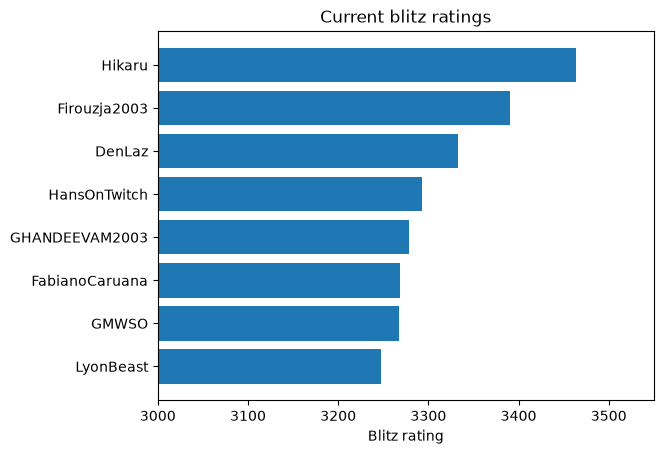

In [32]:
df_blitz = df_ratings.query("time_class == 'blitz'").sort_values("rating")

plt.barh(df_blitz["username"], df_blitz["rating"])
plt.xlim(3000, 3550)
plt.xlabel("Blitz rating")
plt.title("Current blitz ratings")
plt.show()

# <span style="color:red"> Exercises </span>

<font size = "4">

The folder "chess_raw_data" also contains each player's **game archive**: every game they finished in a month, e.g. "games_hikaru_2026_10.json" for October 2026. Magnus Carlsen has archives too ("games_magnuscarlsen_2026_10.json").

Start by choosing a player. Store their username in the variable `username`, spelled as in the table at the top of these notes (or "MagnusCarlsen").

In [ ]:
username = "GHANDEEVAM2003"    # change this to the player you chose

<font size = "4">

**Exercise 1:** Load your player's October 2026 archive, `f"chess_raw_data/games_{username.lower()}_2026_10.json"`, into a variable called `archive`. Then print:

- the keys of the "first level" of `archive`
- the type of `archive["games"]`
- the number of games in `archive["games"]`
- the username of the player with the white pieces in the first game
- the rating of the player with the black pieces in the first game

In [ ]:
# your code here

<font size = "4">

**Exercise 2:** Some games have no "accuracies" key (chess.com's estimate of how well each side played). Write a loop that counts how many games in `archive["games"]` are missing this key. Store the count in a variable called `num_missing` and print it.

In [ ]:
# your code here

<font size = "4">

**Exercise 3:** Write a function `game_to_row(game)` that turns one game into one row (dictionary) with these keys:

"url", "end_time", "time_class", "white_username", "white_rating", "white_result", "white_accuracy", "black_username", "black_rating", "black_result", "black_accuracy"

- Use `.get` for the accuracies, so games without them get `None`.
- Use your function and a loop to create a DataFrame called `df_games` with one row per game in `archive["games"]`.
- Convert the "end_time" column to dates with `pd.to_datetime(..., unit = "s")`.
- Display the first five rows, and print the number of games of each time class with `.value_counts()`.

In [ ]:
# your code here

<font size = "4">

**Exercise 4 (Formula One):** "f1_api_data/results_2025_round1.json" contains the results of the first race of the 2025 season, from the Jolpica F1 API.

- Load the file into a variable called `f1_race` and print its "first level" keys.
- The race is stored at `f1_race["MRData"]["RaceTable"]["Races"][0]`. Store it in a variable called `race`, then print its "raceName" and "date".
- Print the number of results in `race["Results"]`.
- Create a DataFrame called `df_race` with one row per result and the columns "driverId", "constructorId", "grid", "position", and "points". (Each result stores the driver at `["Driver"]["driverId"]` and the constructor at `["Constructor"]["constructorId"]`.)
- The numbers are stored as strings. Convert "grid" and "position" with `.astype(int)` and "points" with `.astype(float)`, then display `df_race`.

In [ ]:
# your code here

<font size = "4">

**Exercise 5 (Formula One):** The API's "driverId" (e.g. "norris") is the same as the "driverRef" column of "f1_raw_data/drivers.csv".

- Rename the "driverId" column of `df_race` to "driverRef".
- Read in "drivers.csv" and merge its columns "driverRef", "forename", "surname", and "nationality" into `df_race`, keeping every row of `df_race`. Call the result `df_race_names` and display it.
- Print the number of rows of `df_race_names` with a missing "forename", using `.isna().sum()`.

Note: drivers who started racing after "drivers.csv" was created have no match, so their names are missing.

In [ ]:
# your code here